# Aula 3 · A cor do rio e a maré

**VERSÃO DO FACILITADOR: tudo resolvido, com notas.** Não copiar para os computadores dos alunos.

**8 minutos (12:35–12:43) · aula guiada, em pares** · a seguir: a Prática 3

**O que vamos fazer:** usar o que aprenderam num assunto novo: a **qualidade da água**. Vamos tentar prever se a água do rio está **turva** (barrenta) de manhã, a partir de dados. Foi isto que fizemos no projecto EYES TO EARTH.

**Os dados:** `cor_do_rio_e_mare.csv` (2 205 linhas: uma manhã num troço do rio, de 2017 a 2026).  
**Treino e teste:** **treino** = as manhãs de 2017 a 2022 (1 214); **teste** = as de 2023 a 2026 (991).  
**O algoritmo:** floresta aleatória com 100 árvores (classificação: água turva ou não).

| Palavra nova | O que quer dizer |
| --- | --- |
| **turbidez** | a água barrenta, cheia de terra fina (sedimentos) |
| **NDTI** | o índice de turbidez que o satélite mede (Módulo 4): mais alto = água mais barrenta |
| **troço** | um pedaço do rio; aqui há três: o troço médio, a jusante e a foz (onde o rio chega ao mar) |
| **turva** | o rótulo: 1 = mais barrenta do que o normal nesse troço; 0 = mais limpa |
| **maré** | o mar sobe e desce duas vezes por dia; mede-se em metros (0 = o nível médio do mar) |

**Como trabalhar:** esta é a **aula guiada**: o facilitador mostra no projector e vocês acompanham.
Cliquem numa célula de código (as cinzentas) e carreguem em **Shift + Enter** para a correr, sempre **por ordem**, de
cima para baixo. A seguir vem a **prática**, em que são vocês a escrever o código. Guardem com **Ctrl + S**.

> **Nota para o facilitador.** Objectivo: uma classificação com os dados da qualidade da água, e a lição do projecto: sem a pista certa (a maré), o modelo não aprende nada útil. Tempo: 8 minutos, no projector. Ligue ao slide do Módulo 4 «A IA consegue prever a água barrenta?». A seguir, a Prática 3: os pares juntam a maré.

## Passo 1 · Abrir as ferramentas

In [1]:
import os, sys
for pasta in [".", os.path.join("..", "..", "2_pratica")]:          # a pasta onde está o ferramentas.py
    if os.path.exists(os.path.join(pasta, "ferramentas.py")):
        sys.path.insert(0, pasta)
        break
from ferramentas import *      # as ferramentas da aula
from sklearn.ensemble import RandomForestClassifier
print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 2 · Dez anos de manhãs no rio

Cada linha é uma manhã em que o satélite Sentinel-2 viu o rio sem nuvens, num dos três troços, de 2017 a 2026. `ndti` é a turbidez medida; `caudal_m3s` e `chuva_7d_mm` são o caudal e a chuva dos últimos 7 dias; `altura_da_mare_m` é a maré à hora do satélite. A coluna `turva` é o **rótulo**.

In [2]:
rio = pd.read_csv(encontrar("cor_do_rio_e_mare.csv"))
print("Linhas na tabela:", numero(len(rio)), "(manhãs de 2017 a 2026, em 3 troços)")
print("Manhãs com a água turva:", percentagem(rio["turva"].mean()))
rio.head()

Linhas na tabela: 2 205 (manhãs de 2017 a 2026, em 3 troços)
Manhãs com a água turva: 56,9 %


,data,ano,mes,troco,ndti,caudal_m3s,chuva_7d_mm,altura_da_mare_m,turva
0,2017-01-06,2017,1,foz,-0.342,54.5,12.7,0.84,0
1,2017-01-06,2017,1,jusante,-0.302,54.5,12.7,0.84,0
2,2017-01-06,2017,1,troço médio,-0.177,54.5,12.7,0.84,0
3,2017-01-19,2017,1,foz,-0.095,141.9,63.4,0.61,1
4,2017-01-19,2017,1,jusante,-0.097,141.9,63.4,0.61,1


## Passo 3 · Separar no tempo: o exame são os anos mais recentes

Queremos um modelo para o futuro. Por isso treinamos com **2017 a 2022** e fazemos o exame com **2023 a 2026**, anos que o modelo nunca vê no treino.

In [3]:
treino = rio[rio["ano"] <= 2022]
teste = rio[rio["ano"] >= 2023]
print("Manhãs de treino (2017 a 2022):", numero(len(treino)))
print("Manhãs de teste (2023 a 2026): ", numero(len(teste)))

Manhãs de treino (2017 a 2022): 1 214
Manhãs de teste (2023 a 2026):  991


## Passo 4 · Primeira tentativa: o caudal, a chuva e o mês

Parece lógico: depois de muita chuva, o rio traz mais terra. Damos à floresta aleatória (Tema 2) três pistas: o caudal, a chuva dos últimos 7 dias e o mês.

In [4]:
PISTAS_SEM_MARE = ["caudal_m3s", "chuva_7d_mm", "mes"]
floresta = RandomForestClassifier(n_estimators=100, random_state=0)
floresta.fit(treino[PISTAS_SEM_MARE], treino["turva"])
nota_sem_mare = acerto(teste["turva"], floresta.predict(teste[PISTAS_SEM_MARE]))
sempre_turva = teste["turva"].mean()        # a nota de quem diz sempre «turva», sem modelo nenhum
print("Acerto no teste, sem a maré:   ", percentagem(nota_sem_mare))
print("Se disséssemos sempre «turva»: ", percentagem(sempre_turva))

Acerto no teste, sem a maré:    64,6 %
Se disséssemos sempre «turva»:  65,6 %


A floresta acerta **menos** do que dizer sempre «turva». Com estas pistas, a máquina **não aprendeu nada útil**, e mais árvores não resolvem. **Falta uma pista.**

> **Nota para o facilitador.** Resultado esperado: 64,6 % sem a maré, contra 65,6 % de «dizer sempre turva». Pergunte à turma: "o que pode mudar a cor da água perto do mar, de um dia para o outro?" Deixe-os pensar antes do Passo 5.

## Passo 5 · A pista que faltava: a maré

A foz do Incomáti fica no mar, e o mar sobe e desce duas vezes por dia. A tabela tem a altura da maré à hora em que o satélite passou (cerca das 9:30). Vejamos a turbidez em cada altura da maré.

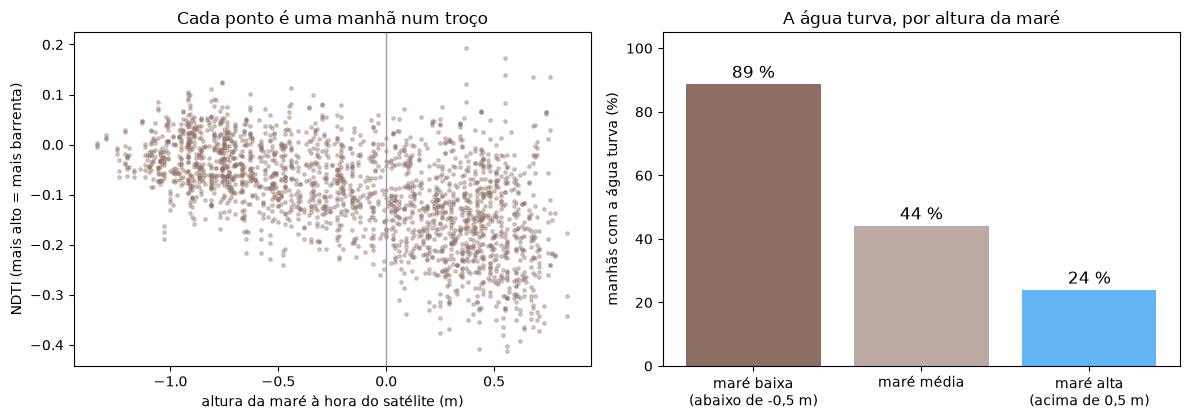

maré baixa   89 % das manhãs com a água turva
maré média   44 % das manhãs com a água turva
maré alta    24 % das manhãs com a água turva


In [5]:
ver_mare(rio)

Com a **maré baixa**, a água está quase sempre turva; com a **maré alta**, quase sempre mais limpa. Uma explicação simples: na maré alta entra água do mar, mais limpa; na maré baixa sai a água barrenta do rio.

No projecto EYES TO EARTH aconteceu o mesmo: o modelo da água barrenta só começou a funcionar quando lhe demos a maré. **Na Prática 3, são vocês que juntam a maré ao modelo.**

> **Nota para o facilitador.** Resultado esperado: água turva em 89 % das manhãs de maré baixa, 44 % na maré média e 24 % na maré alta. A maré é calculada para a baía de Maputo à hora do satélite (o modelo de marés do projecto). No projecto, o modelo final da turbidez (com a maré e a última medição do satélite) chega a ROC-AUC 0,88 e é o que a plataforma usa.

## O que aprendemos

- Treinámos uma **classificação** (turva ou não) com os dados de um assunto novo: a qualidade da água.
- Com o caudal, a chuva e o mês, o modelo acerta **menos** do que «dizer sempre turva». Comparem sempre o modelo com «não fazer nada».
- O gráfico mostrou a pista que faltava: a **maré**. Escolher as pistas certas vale mais do que o algoritmo.

## Guardar os modelos e as separações (só na versão do facilitador)

Ficam nas pastas `modelos_treinados/` e `separacoes/`, ao lado deste notebook. Para usar um modelo noutro notebook: `modelo = joblib.load("modelos_treinados/...joblib")`.

In [6]:
import joblib
os.makedirs("modelos_treinados", exist_ok=True)
os.makedirs("separacoes", exist_ok=True)
joblib.dump(floresta, "modelos_treinados/aula3_floresta_sem_mare.joblib")
treino.to_csv("separacoes/aula3_treino_2017_a_2022.csv", index=False)
teste.to_csv("separacoes/aula3_teste_2023_a_2026.csv", index=False)
print("Guardado em modelos_treinados/ e separacoes/.")

Guardado em modelos_treinados/ e separacoes/.


## Se aparecer um erro

Leiam a **última linha** da mensagem vermelha.

| A última linha diz | O que fazer |
| --- | --- |
| `NameError: name '...' is not defined` | Saltaram uma célula. Corram as células por ordem, a partir do Passo 1. |
| `FileNotFoundError: Não encontrei ...` | Abram o notebook a partir da pasta `Workshop_2/2_pratica`. |
| `ModuleNotFoundError` | Falta uma biblioteca neste computador: chamem um facilitador. |
| `NotFittedError` ou «O modelo ainda não foi treinado» | Falta treinar o modelo: corram a célula com `.fit(...)`. |
| `SyntaxError` | Falta uma aspa, um parêntese ou uma vírgula. Comparem com o exemplo. |
| «Falta preencher» | Troquem os `...` pela vossa resposta. |

Se nada resultar: menu **Kernel**, depois **Restart Kernel and Run All Cells**.